# Trabajo Final Integrador  
## Estimación de la producción mensual de petróleo en pozos Shale de Vaca Muerta mediante Machine Learning

### Introducción

La producción mensual de petróleo de un pozo puede variar por condiciones operativas y por características propias del pozo.  
En este trabajo se analiza si modelos de Machine Learning pueden **estimar la producción mensual de petróleo** utilizando información pública de pozos asociados a la formación **Vaca Muerta**.

Para obtener una población más homogénea, el análisis se limita a:

- Formación: **Vaca Muerta**
- Tipo de recurso: **No convencional**
- Subtipo de recurso: **SHALE**
- Tipo de pozo: **Petrolífero**
- Estado: **Extracción Efectiva**

### Objetivo general

Desarrollar y comparar modelos de regresión capaces de estimar la producción mensual de petróleo (`prod_pet`) a partir de variables operativas y técnicas disponibles en el dataset.

### Objetivos específicos

1. Obtener y explorar los datos desde una fuente pública.
2. Delimitar una población coherente para el problema.
3. Preparar las variables para Machine Learning.
4. Separar entrenamiento y prueba por pozo, evitando que un mismo pozo aparezca en ambos conjuntos.
5. Comparar un baseline, una regresión lineal y un árbol de decisión.
6. Analizar si agregar empresa y área/yacimiento mejora los modelos.
7. Interpretar resultados, limitaciones y posibles mejoras.

## 1. Descripción del dataset

La fuente utilizada es una tabla pública de la **Secretaría de Energía de la Nación** publicada mediante un servicio ArcGIS REST:

`Producción de pozos - Junio 2026`

La tabla contiene registros mensuales por pozo e incluye, entre otras, las siguientes variables:

| Variable | Descripción |
|---|---|
| `anio` | Año del registro |
| `mes` | Mes del registro |
| `idpozo` | Identificador del pozo |
| `prod_pet` | Producción mensual de petróleo |
| `prod_gas` | Producción mensual de gas |
| `tef` | Tiempo efectivo de funcionamiento |
| `tipoextraccion` | Sistema de extracción |
| `tipoestado` | Estado operativo del pozo |
| `tipopozo` | Tipo de pozo |
| `empresa` | Empresa operadora |
| `profundidad` | Profundidad del pozo |
| `formacion` | Formación geológica |
| `areayacimiento` | Área o yacimiento |
| `tipo_de_recurso` | Convencional / no convencional |
| `sub_tipo_recurso` | SHALE / TIGHT / otros |

**Variable objetivo:** `prod_pet`.

> El servicio limita cada consulta a 2.000 registros, por lo que la descarga se realiza por bloques.

In [1]:
# Librerías utilizadas en el trabajo

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

pd.set_option("display.max_columns", None)

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Pandas: 2.2.3
NumPy: 2.1.3


In [2]:
# Endpoint oficial de consulta

URL_API = (
    "https://services1.arcgis.com/"
    "gKFHG0iKXPnKkg1l/"
    "ArcGIS/rest/services/"
    "Hidrocarburos_Argentina_SENRes319/"
    "FeatureServer/9/query"
)

# Campos que utilizaremos.
# Se incluye OBJECTID para ordenar la descarga por bloques.
campos = [
    "OBJECTID",
    "anio",
    "mes",
    "idpozo",
    "prod_pet",
    "prod_gas",
    "prod_agua",
    "tef",
    "tipoextraccion",
    "tipoestado",
    "tipopozo",
    "empresa",
    "formprod",
    "profundidad",
    "formacion",
    "areayacimiento",
    "cuenca",
    "provincia",
    "tipo_de_recurso",
    "sub_tipo_recurso"
]

campos_api = ",".join(campos)

print("API configurada correctamente.")

API configurada correctamente.


## 1.1 Descarga de los registros de Vaca Muerta shale

Para no descargar información que no pertenece al problema, la consulta aplica desde el origen los siguientes filtros:

- `formacion = 'vaca muerta'`
- `tipo_de_recurso = 'NO CONVENCIONAL'`
- `sub_tipo_recurso = 'SHALE'`

Luego, dentro de Python, se realizará una segunda delimitación por tipo y estado del pozo.

In [3]:
# Filtro principal aplicado en la API

filtro_vm = (
    "formacion='vaca muerta' "
    "AND tipo_de_recurso='NO CONVENCIONAL' "
    "AND sub_tipo_recurso='SHALE'"
)

# Primero consultamos cuántos registros cumplen el filtro.
parametros_conteo = {
    "where": filtro_vm,
    "returnCountOnly": "true",
    "f": "json"
}

respuesta_conteo = requests.get(
    URL_API,
    params=parametros_conteo,
    timeout=60
)

respuesta_conteo.raise_for_status()
cantidad_vm_shale = respuesta_conteo.json()["count"]

print(
    "Registros Vaca Muerta - NO CONVENCIONAL - SHALE:",
    f"{cantidad_vm_shale:,}"
)

Registros Vaca Muerta - NO CONVENCIONAL - SHALE: 18,857


In [4]:
# Descarga por bloques de hasta 2.000 registros.
# La paginación permite superar el límite del servicio ArcGIS.

todos_registros = []
offset = 0
tamanio_bloque = 2000

while True:
    parametros = {
        "where": filtro_vm,
        "outFields": campos_api,
        "returnGeometry": "false",
        "resultOffset": offset,
        "resultRecordCount": tamanio_bloque,
        "orderByFields": "OBJECTID",
        "f": "json"
    }

    respuesta = requests.get(
        URL_API,
        params=parametros,
        timeout=60
    )
    respuesta.raise_for_status()

    datos = respuesta.json()

    if "error" in datos:
        raise RuntimeError(datos["error"])

    features = datos.get("features", [])

    if len(features) == 0:
        break

    bloque = [
        registro["attributes"]
        for registro in features
    ]

    todos_registros.extend(bloque)

    print(
        f"Descargados: {len(todos_registros):,} "
        f"de {cantidad_vm_shale:,}"
    )

    if len(features) < tamanio_bloque:
        break

    offset += tamanio_bloque

df_vm = pd.DataFrame(todos_registros)

print("\nDimensiones del dataset:", df_vm.shape)
display(df_vm.head())

Descargados: 2,000 de 18,857
Descargados: 4,000 de 18,857
Descargados: 6,000 de 18,857
Descargados: 8,000 de 18,857
Descargados: 10,000 de 18,857
Descargados: 12,000 de 18,857
Descargados: 14,000 de 18,857
Descargados: 16,000 de 18,857
Descargados: 18,000 de 18,857
Descargados: 18,857 de 18,857

Dimensiones del dataset: (18857, 20)


,OBJECTID,anio,mes,idpozo,prod_pet,prod_gas,prod_agua,tef,tipoextraccion,tipoestado,tipopozo,empresa,formprod,profundidad,formacion,areayacimiento,cuenca,provincia,tipo_de_recurso,sub_tipo_recurso
0,138,2026,1,145871,0,0,0,0,Bombeo Mecánico,A Abandonar,Otro tipo,YPF S.A.,VMUT,3172.0,vaca muerta,LOMA CAMPANA-LLL,NEUQUINA,Neuquén,NO CONVENCIONAL,SHALE
1,144,2026,1,162214,830,56,6,31,Bombeo Mecánico,Extracción Efectiva,Petrolífero,YPF S.A.,VMUT,5123.0,vaca muerta,LOMA CAMPANA-LLL,NEUQUINA,Neuquén,NO CONVENCIONAL,SHALE
2,154,2026,1,154203,2,8,0,31,Plunger Lift,Extracción Efectiva,Petrolífero,YPF S.A.,VMUT,3004.0,vaca muerta,LOMA CAMPANA-LLL,NEUQUINA,Neuquén,NO CONVENCIONAL,SHALE
3,167,2026,1,164790,926,144,267,28,Surgencia Natural,Extracción Efectiva,Petrolífero,YPF S.A.,VMUT,5408.0,vaca muerta,BAJO DEL TORO NORTE,NEUQUINA,Neuquén,NO CONVENCIONAL,SHALE
4,180,2026,1,161950,775,121,113,29,Bombeo Mecánico,Extracción Efectiva,Petrolífero,YPF S.A.,VMUT,6258.0,vaca muerta,LA AMARGA CHICA,NEUQUINA,Neuquén,NO CONVENCIONAL,SHALE


# 2. Exploración y delimitación de la población

En la exploración inicial se comprobó que los registros shale incluyen pozos petrolíferos, gasíferos y otros tipos.

Como el objetivo es estimar producción de petróleo, se seleccionan únicamente:

1. pozos `Petrolífero`;
2. en estado `Extracción Efectiva`.

Esta decisión evita mezclar en el mismo problema pozos gasíferos, abandonados, detenidos o instalaciones con otra función.

In [5]:
# Conversión explícita de variables numéricas.
# errors="coerce" transforma valores inválidos en NaN para poder detectarlos.

columnas_numericas = [
    "anio",
    "mes",
    "idpozo",
    "prod_pet",
    "prod_gas",
    "prod_agua",
    "tef",
    "profundidad"
]

for columna in columnas_numericas:
    df_vm[columna] = pd.to_numeric(
        df_vm[columna],
        errors="coerce"
    )

print("Registros SHALE:", f"{len(df_vm):,}")
print("Pozos diferentes:", f"{df_vm['idpozo'].nunique():,}")

print("\nTipos de pozo:")
display(
    df_vm["tipopozo"]
    .value_counts(dropna=False)
    .to_frame("cantidad")
)

Registros SHALE: 18,857
Pozos diferentes: 3,278

Tipos de pozo:


,cantidad
tipopozo,
Petrolífero,13295
Gasífero,4279
Otro tipo,1243
Sumidero,23
None,17


In [6]:
# Delimitación final de la población del TFI

df_pet = df_vm[
    df_vm["tipopozo"] == "Petrolífero"
].copy()

df_modelo = df_pet[
    df_pet["tipoestado"] == "Extracción Efectiva"
].copy()

ceros = (df_modelo["prod_pet"] == 0).sum()
porcentaje_ceros = ceros / len(df_modelo) * 100

resumen_poblacion = pd.DataFrame({
    "Etapa": [
        "Vaca Muerta - No convencional - SHALE",
        "Pozos petrolíferos",
        "Petrolíferos en extracción efectiva"
    ],
    "Registros": [
        len(df_vm),
        len(df_pet),
        len(df_modelo)
    ]
})

display(resumen_poblacion)

print("Pozos únicos activos:", f"{df_modelo['idpozo'].nunique():,}")
print(
    "Producción cero en extracción efectiva:",
    f"{ceros:,}",
    f"({porcentaje_ceros:.2f}%)"
)

,Etapa,Registros
0,Vaca Muerta - No convencional - SHALE,18857
1,Pozos petrolíferos,13295
2,Petrolíferos en extracción efectiva,12321


Pozos únicos activos: 2,212
Producción cero en extracción efectiva: 193 (1.57%)


### Resultado de la delimitación obtenida durante el desarrollo

En la ejecución realizada para este trabajo se obtuvieron:

- 18.857 registros Vaca Muerta shale.
- 3.278 pozos diferentes en la población shale.
- 13.295 registros correspondientes a pozos petrolíferos.
- 12.321 registros de pozos petrolíferos en extracción efectiva.
- 2.212 pozos únicos en la población final.
- Solo **193 registros (1,57 %)** de la población final presentaron `prod_pet = 0`.

Esta reducción es una mejora y aumentaria la coherencia del problema antes de entrenar modelo o modelos.

## 2.1 Calidad de las variables y análisis exploratorio

Antes de entrenar modelos se revisan:

- datos faltantes;
- cantidad de valores únicos;
- distribución de la producción;
- sistemas de extracción;
- correlaciones simples entre variables numéricas.

El objetivo es conocer la estructura básica de los datos.

In [7]:
variables_candidatas = [
    "mes",
    "tef",
    "profundidad",
    "tipoextraccion",
    "empresa",
    "formprod",
    "areayacimiento",
    "prod_pet"
]

calidad = pd.DataFrame({
    "faltantes":
        df_modelo[variables_candidatas]
        .isna()
        .sum(),

    "porcentaje_faltantes":
        (
            df_modelo[variables_candidatas]
            .isna()
            .mean()
            * 100
        ).round(2),

    "valores_unicos":
        df_modelo[variables_candidatas]
        .nunique()
})

display(calidad)

,faltantes,porcentaje_faltantes,valores_unicos
mes,0,0.0,6
tef,0,0.0,32
profundidad,0,0.0,1475
tipoextraccion,0,0.0,6
empresa,0,0.0,21
formprod,0,0.0,1
areayacimiento,0,0.0,52
prod_pet,0,0.0,3720


In [8]:
# Estadísticas de la variable objetivo

display(
    df_modelo["prod_pet"]
    .describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)

# Distribución de tipos de extracción
display(
    df_modelo["tipoextraccion"]
    .value_counts()
    .to_frame("cantidad")
)

,prod_pet
count,12321.000000
mean,1284.954468
std,1685.077913
min,0.000000
25%,191.000000
50%,698.000000
75%,1631.000000
90%,3307.000000
95%,4918.000000
99%,8037.800000


,cantidad
tipoextraccion,
Surgencia Natural,5507
Bombeo Mecánico,3793
Gas Lift,1497
Plunger Lift,1459
Electrosumergible,59
Sin Sistema de Extracción,6


In [9]:
# Correlaciones entre variables numéricas.
# Pearson mide asociación lineal; no implica causa del dato.

variables_correlacion = [
    "mes",
    "tef",
    "profundidad",
    "prod_pet"
]

matriz_correlacion = (
    df_modelo[variables_correlacion]
    .corr()
)

display(matriz_correlacion.round(3))

,mes,tef,profundidad,prod_pet
mes,1.000,0.004,0.018,-0.003
tef,0.004,1.000,-0.005,0.202
profundidad,0.018,-0.005,1.000,0.325
prod_pet,-0.003,0.202,0.325,1.000


### Resultados exploratorios relevantes

Durante el desarrollo se observaron las siguientes correlaciones con `prod_pet`:

- `mes`: **-0,003**
- `tef`: **0,202**
- `profundidad`: **0,325**

La profundidad presentó la mayor asociación lineal individual, aunque todavía moderada.

También se observaron los siguientes sistemas de extracción en la población final:

- Surgencia Natural: 5.507
- Bombeo Mecánico: 3.793
- Gas Lift: 1.497
- Plunger Lift: 1.459
- Electrosumergible: 59
- Sin Sistema de Extracción: 6

Se evidencia Una correlación baja de la variable: se consiedra que un modelo no lineal puede detectar relaciones e interacciones que Pearson puediera no tener represente.

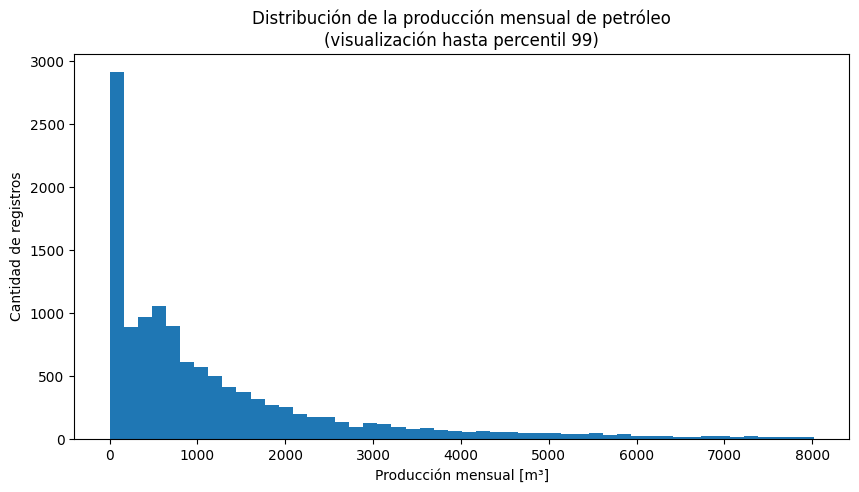

In [10]:
# Visualización 1: distribución de la producción.
# Para que el gráfico sea legible se recorta solamente la visualización en P99.
# Los datos del modelo NO se eliminan.

p99 = df_modelo["prod_pet"].quantile(0.99)

plt.figure(figsize=(10, 5))

plt.hist(
    df_modelo.loc[
        df_modelo["prod_pet"] <= p99,
        "prod_pet"
    ],
    bins=50
)

plt.title(
    "Distribución de la producción mensual de petróleo\n"
    "(visualización hasta percentil 99)"
)
plt.xlabel("Producción mensual [m³]")
plt.ylabel("Cantidad de registros")
plt.show()

# 3. Metodología aplicada

Se comparan tres niveles de modelo:

1. **Baseline — DummyRegressor:** la idea es pedecir la mediana del conjunto de entrenamiento.
2. **Regresión lineal:** modelo sencillo e interpretable esperamos presentar las relaciones lineales.
3. **Árbol de decisión:** modelo no lineal capaz de aprender reglas e interacciones entre variables.

### Variables del primer experimento

**Predictoras (`X`):**

- `mes`
- `tef`
- `profundidad`
- `tipoextraccion`

**Objetivo (`y`):**

- `prod_pet`

`idpozo` no se utiliza como predictor porque es un identificador y podría causar un efecto negativo al favorecer la memorización.

`formprod` tampoco se utiliza ya que es un único valor.

### Separación de entrenamiento y prueba

El mismo pozo puede aparecer en varios meses.  
Por este motivo no se realiza una separación aleatoria por fila

Se utiliza `GroupShuffleSplit` con `idpozo` como grupo, de modo que un pozo completo quede solamente en TRAIN o solamente en TEST.

Esto permite evaluar el modelo sobre pozos que no participaron del entrenamiento.

In [11]:
# Definición de variables del experimento básico

variables_modelo_1 = [
    "mes",
    "tef",
    "profundidad",
    "tipoextraccion"
]

X = df_modelo[variables_modelo_1].copy()
y = df_modelo["prod_pet"].copy()
grupos = df_modelo["idpozo"].copy()

# Separación aproximada 80/20 por pozo
separador = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    separador.split(
        X,
        y,
        groups=grupos
    )
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

grupos_train = grupos.iloc[train_idx]
grupos_test = grupos.iloc[test_idx]

pozos_train = set(grupos_train.unique())
pozos_test = set(grupos_test.unique())

print("Registros TRAIN:", len(X_train))
print("Registros TEST:", len(X_test))
print("Pozos TRAIN:", len(pozos_train))
print("Pozos TEST:", len(pozos_test))
print(
    "Pozos compartidos:",
    len(pozos_train.intersection(pozos_test))
)

Registros TRAIN: 9833
Registros TEST: 2488
Pozos TRAIN: 1769
Pozos TEST: 443
Pozos compartidos: 0


El valor **Pozos compartidos** debe ser `0`.  
Si fuera mayor que cero, existiría contaminación entre entrenamiento y prueba y no se podria avanzar +

In [12]:
# Preprocesamiento:
# - TEF y profundidad se consideran numéricas.
# - Mes y tipo de extracción se consideran categóricas.

variables_numericas = [
    "tef",
    "profundidad"
]

variables_categoricas = [
    "mes",
    "tipoextraccion"
]

preprocesador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            StandardScaler(),
            variables_numericas
        ),
        (
            "categoricas",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            variables_categoricas
        )
    ]
)

In [13]:
# Función común para evaluar todos los modelos con las mismas métricas.

def evaluar_modelo(nombre, y_real, y_predicho):
    mae = mean_absolute_error(
        y_real,
        y_predicho
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_real,
            y_predicho
        )
    )

    r2 = r2_score(
        y_real,
        y_predicho
    )

    return {
        "Modelo": nombre,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

## 3.1 Modelo 0 — Baseline

El baseline no utiliza las variables predictoras.  
Su función es responder una pregunta simple:

> ¿Los modelos de Machine Learning son capaces de predecir siempre un valor típico?

Se utiliza la mediana de la producción del conjunto de entrenamiento.

In [14]:
modelo_dummy = DummyRegressor(
    strategy="median"
)

modelo_dummy.fit(
    X_train,
    y_train
)

pred_dummy = modelo_dummy.predict(
    X_test
)

resultado_dummy = evaluar_modelo(
    "Baseline - Mediana",
    y_test,
    pred_dummy
)

resultado_dummy

{'Modelo': 'Baseline - Mediana',
 'MAE': 1014.0643086816721,
 'RMSE': np.float64(1770.3025553446528),
 'R2': -0.09920542346888017}

## 3.2 Modelo 1 — Regresión lineal

La regresión lineal intenta explicar la producción como una combinación lineal de las variables.

Es un modelo útil como referencia porque es rápido, sencillo y relativamente fácil de interpretar.

In [15]:
modelo_lineal = Pipeline(
    steps=[
        (
            "preprocesamiento",
            preprocesador
        ),
        (
            "modelo",
            LinearRegression()
        )
    ]
)

modelo_lineal.fit(
    X_train,
    y_train
)

pred_lineal = modelo_lineal.predict(
    X_test
)

resultado_lineal = evaluar_modelo(
    "Regresión Lineal",
    y_test,
    pred_lineal
)

resultado_lineal

{'Modelo': 'Regresión Lineal',
 'MAE': 874.7397398910808,
 'RMSE': np.float64(1380.8588995574578),
 'R2': 0.3312212324619609}

## 3.3 Modelo 2 — Árbol de decisión

El árbol de decisión puede representar relaciones no lineales y combinaciones entre variables.

Se limita su complejidad para reducir el riesgo de sobreajuste:

- `max_depth = 6`
- `min_samples_leaf = 20`
la idea es que no tengamos un arbol gigantesco con muchas  ramas con valores unicos

In [16]:
modelo_arbol = Pipeline(
    steps=[
        (
            "preprocesamiento",
            preprocesador
        ),
        (
            "modelo",
            DecisionTreeRegressor(
                max_depth=6,
                min_samples_leaf=20,
                random_state=42
            )
        )
    ]
)

modelo_arbol.fit(
    X_train,
    y_train
)

pred_arbol = modelo_arbol.predict(
    X_test
)

resultado_arbol = evaluar_modelo(
    "Árbol de Decisión",
    y_test,
    pred_arbol
)

resultado_arbol

{'Modelo': 'Árbol de Decisión',
 'MAE': 703.0848384984988,
 'RMSE': np.float64(1222.1075248331288),
 'R2': 0.4761551165488399}

# 4. Resultados y métricas de evaluación

Se utilizan tres métricas:

- **MAE:** error absoluto medio. Cuanto menor, mejor.
- **RMSE:** penaliza con mayor fuerza los errores grandes. Cuanto menor, mejor.
- **R²:** indica qué proporción de la variabilidad logra representar el modelo. Cuanto más próximo a 1, mejor.

Las métricas deben analizarse en conjunto.

,Modelo,MAE,RMSE,R2
0,Baseline - Mediana,1014.06,1770.30,-0.10
1,Regresión Lineal,874.74,1380.86,0.33
2,Árbol de Decisión,703.08,1222.11,0.48


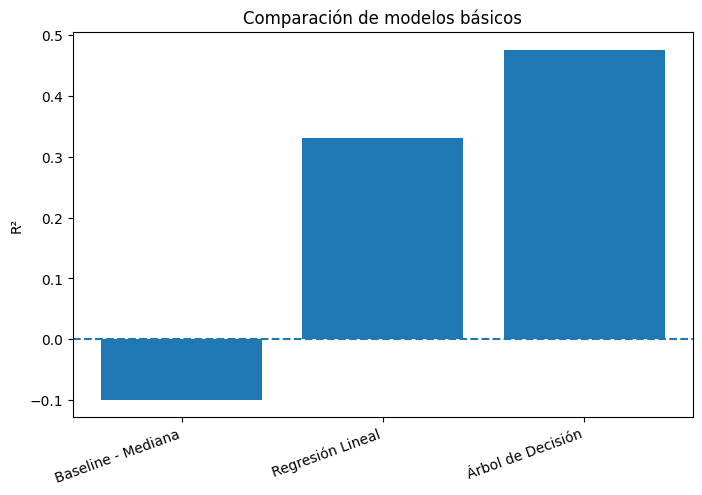

In [17]:
resultados_basicos = pd.DataFrame([
    resultado_dummy,
    resultado_lineal,
    resultado_arbol
])

display(
    resultados_basicos.round(2)
)

# Gráfico de R² para comparar rápidamente los modelos.
plt.figure(figsize=(8, 5))

plt.bar(
    resultados_basicos["Modelo"],
    resultados_basicos["R2"]
)

plt.axhline(
    0,
    linestyle="--"
)

plt.ylabel("R²")
plt.title("Comparación de modelos básicos")
plt.xticks(rotation=20, ha="right")
plt.show()

### Resultados obtenidos en el desarrollo

| Modelo | MAE [m³] | RMSE [m³] | R² |
|---|---:|---:|---:|
| Baseline – Mediana | 1.014,06 | 1.770,30 | -0,10 |
| Regresión Lineal | 874,74 | 1.380,86 | 0,33 |
| Árbol de Decisión | **703,08** | **1.222,11** | **0,48** |

### Lectura inicial

- El **baseline** presenta un desempeño pobre. Su R² negativo indica que predecir una constante no representa adecuadamente la variabilidad de los pozos.
- La **regresión lineal** mejora claramente al baseline y demuestra que las variables parecen contener información predictiva.
- El **árbol de decisión** obtiene el mejor desempeño global. Esto sugiere que existen relaciones no lineales e interacciones que la regresión lineal analizar completamente.

## 4.1 Control de sobreajuste del árbol

Se considera que un árbol puede aprender demasiado bien los datos de entrenamiento.
Por eso se comparan las métricas de TRAIN y TEST.

In [18]:
pred_arbol_train = modelo_arbol.predict(
    X_train
)

resultado_arbol_train = evaluar_modelo(
    "Árbol - TRAIN",
    y_train,
    pred_arbol_train
)

resultado_arbol_test = evaluar_modelo(
    "Árbol - TEST",
    y_test,
    pred_arbol
)

comparacion_arbol = pd.DataFrame([
    resultado_arbol_train,
    resultado_arbol_test
])

display(
    comparacion_arbol.round(2)
)

,Modelo,MAE,RMSE,R2
0,Árbol - TRAIN,656.30,1163.49,0.52
1,Árbol - TEST,703.08,1222.11,0.48


En el desarrollo se obtuvieron:

| Conjunto | MAE | RMSE | R² |
|---|---:|---:|---:|
| TRAIN | 656,30 | 1.163,49 | 0,52 |
| TEST | 703,08 | 1.222,11 | 0,48 |

La diferencia entre TRAIN y TEST es moderada.  
No se observa un sobreajuste severo para la configuración utilizada.

## 4.2 Experimento adicional — empresa y área/yacimiento

Para estudiar si el contexto aporta capacidad predictiva se agregan:

- `empresa`
- `areayacimiento`

La separación TRAIN/TEST se mantiene exactamente igual, lo que permite comparar los modelos de forma justa.

In [19]:
variables_modelo_2 = [
    "mes",
    "tef",
    "profundidad",
    "tipoextraccion",
    "empresa",
    "areayacimiento"
]

X2 = df_modelo[variables_modelo_2].copy()

X2_train = X2.iloc[train_idx].copy()
X2_test = X2.iloc[test_idx].copy()

variables_numericas_2 = [
    "tef",
    "profundidad"
]

variables_categoricas_2 = [
    "mes",
    "tipoextraccion",
    "empresa",
    "areayacimiento"
]

preprocesador_2 = ColumnTransformer(
    transformers=[
        (
            "numericas",
            StandardScaler(),
            variables_numericas_2
        ),
        (
            "categoricas",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            variables_categoricas_2
        )
    ]
)

modelo_lineal_2 = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador_2),
        ("modelo", LinearRegression())
    ]
)

modelo_arbol_2 = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador_2),
        (
            "modelo",
            DecisionTreeRegressor(
                max_depth=6,
                min_samples_leaf=20,
                random_state=42
            )
        )
    ]
)

# Entrenamiento
modelo_lineal_2.fit(X2_train, y_train)
modelo_arbol_2.fit(X2_train, y_train)

# Predicciones
pred_lineal_2 = modelo_lineal_2.predict(X2_test)
pred_arbol_2 = modelo_arbol_2.predict(X2_test)

# Evaluación
resultado_lineal_2 = evaluar_modelo(
    "Lineal + contexto",
    y_test,
    pred_lineal_2
)

resultado_arbol_2 = evaluar_modelo(
    "Árbol + contexto",
    y_test,
    pred_arbol_2
)

comparacion_experimentos = pd.DataFrame([
    resultado_dummy,
    resultado_lineal,
    resultado_arbol,
    resultado_lineal_2,
    resultado_arbol_2
])

display(
    comparacion_experimentos.round(2)
)

,Modelo,MAE,RMSE,R2
0,Baseline - Mediana,1014.06,1770.30,-0.10
1,Regresión Lineal,874.74,1380.86,0.33
2,Árbol de Decisión,703.08,1222.11,0.48
3,Lineal + contexto,805.68,1297.88,0.41
4,Árbol + contexto,685.92,1228.91,0.47


### Comparación completa obtenida

| Modelo | MAE [m³] | RMSE [m³] | R² |
|---|---:|---:|---:|
| Baseline – Mediana | 1.014,06 | 1.770,30 | -0,10 |
| Regresión Lineal | 874,74 | 1.380,86 | 0,33 |
| Árbol de Decisión | 703,08 | **1.222,11** | **0,48** |
| Lineal + contexto | 805,68 | 1.297,88 | 0,41 |
| Árbol + contexto | **685,92** | 1.228,91 | 0,47 |

La incorporación de empresa y área/yacimiento mejora de forma clara la regresión lineal.

En el árbol, el MAE disminuye ligeramente, pero RMSE y R² no mejoran.  
Por este motivo se considera al **árbol básico** como el mejor equilibrio entre desempeño, simplicidad e facilidad de interpretacion de sus resultados

## 4.3 Producción real frente a producción estimada

El siguiente gráfico compara la producción real con la estimada por el árbol básico.

La línea diagonal representa una predicción ideal: cuanto más cerca se encuentre un punto de esa línea, menor es el error.

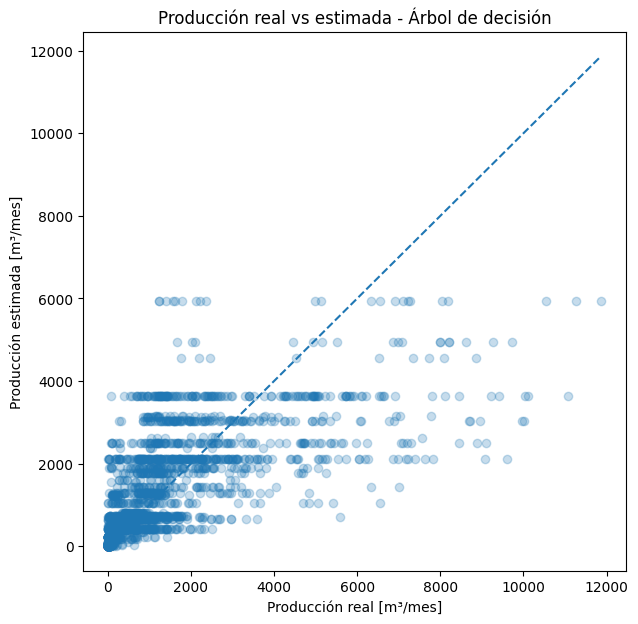

In [20]:
plt.figure(figsize=(7, 7))

plt.scatter(
    y_test,
    pred_arbol,
    alpha=0.25
)

limite = max(
    y_test.max(),
    pred_arbol.max()
)

plt.plot(
    [0, limite],
    [0, limite],
    linestyle="--"
)

plt.xlabel("Producción real [m³/mes]")
plt.ylabel("Producción estimada [m³/mes]")
plt.title("Producción real vs estimada - Árbol de decisión")
plt.show()

## 4.4 Importancia de variables del árbol

La importancia de variables indica cuánto utiliza el árbol cada variable para realizar divisiones que reducen el error.

**Aunque NO deberia interpretarse como causalidad.**

,variable,importancia
12,categoricas__tipoextraccion_Surgencia Natural,0.407089
1,numericas__profundidad,0.370897
0,numericas__tef,0.181501
8,categoricas__tipoextraccion_Bombeo Mecánico,0.022306
11,categoricas__tipoextraccion_Plunger Lift,0.012510
9,categoricas__tipoextraccion_Electrosumergible,0.003556
3,categoricas__mes_2,0.001870
7,categoricas__mes_6,0.000271
2,categoricas__mes_1,0.000000
4,categoricas__mes_3,0.000000


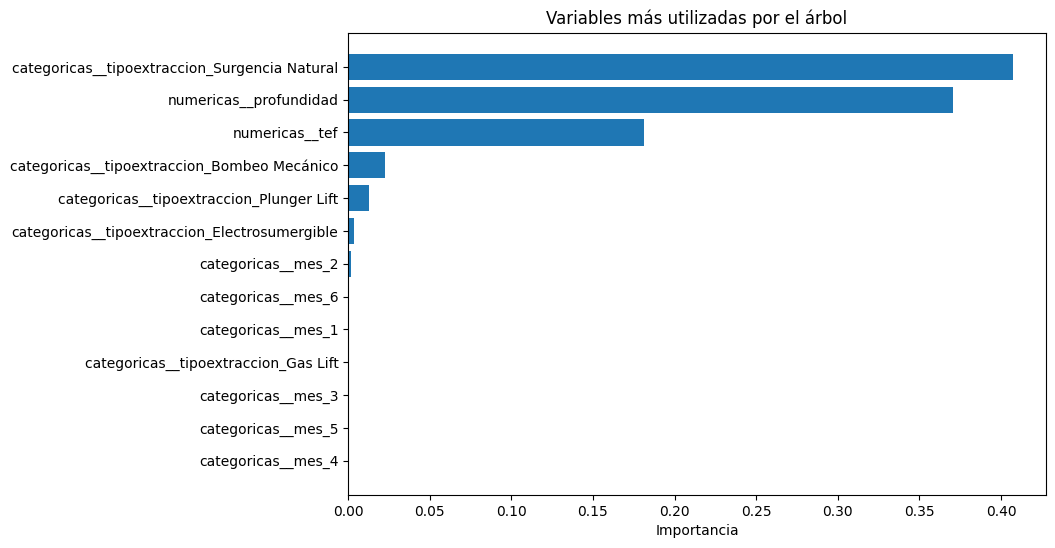

In [21]:
preprocesamiento_entrenado = (
    modelo_arbol
    .named_steps["preprocesamiento"]
)

nombres_variables = (
    preprocesamiento_entrenado
    .get_feature_names_out()
)

arbol_entrenado = (
    modelo_arbol
    .named_steps["modelo"]
)

importancias = pd.DataFrame({
    "variable": nombres_variables,
    "importancia": arbol_entrenado.feature_importances_
})

importancias = (
    importancias
    .sort_values(
        "importancia",
        ascending=False
    )
)

display(
    importancias.head(15)
)

top_importancias = (
    importancias
    .head(15)
    .sort_values("importancia")
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_importancias["variable"],
    top_importancias["importancia"]
)

plt.xlabel("Importancia")
plt.title("Variables más utilizadas por el árbol")
plt.show()

# 5. Interpretación de los modelos y criterios de uso

## Baseline — DummyRegressor

**Función:** servir como referencia mínima (Mediana).

No es un modelo adecuado para uso operativo.  
Permite comprobar si los modelos entrenados realmente extraen información útil de los datos.

---

## Regresión Lineal

**Ventajas**

- simple;
- rápida;
- fácil de explicar;
- útil como primera aproximación.

**Limitaciones**

- representa principalmente relaciones lineales;
- tiene dificultad para capturar interacciones complejas.

**Resultado:** `R² = 0,33`.

**Criterio de uso:** recomendable cuando se prioriza simplicidad e interpretabilidad y el desempeño predictivo no es el único objetivo.

---

## Regresión Lineal + contexto

Agregar empresa y área/yacimiento mejoró el modelo:

- MAE: `874,74 → 805,68`
- R²: `0,33 → 0,41`

Esto indica que el contexto geográfico y operativo aporta información adicional.

**Criterio de uso:** es un modelo relativamente sencillo pero incorporar información del contexto productivo.

---

## Árbol de Decisión

El árbol básico obtuvo:

- **MAE = 703,08 m³/mes**
- **RMSE = 1.222,11 m³/mes**
- **R² = 0,48**

Su desempeño fue superior al de la regresión lineal.

**Ventajas**

- aprende relaciones no lineales;
- representa interacciones;
- sigue siendo relativamente facil de interpretar.

**Limitaciones**

- puede sobreajustarse;
- puede ser sensible a cambios en los datos;
- puede tener errores importantes en producciones extremas.

**Criterio de uso:** es el modelo elegido en este trabajo porque ofrece el mejor equilibrio entre desempeño, simplicidad e interpretabilidad.

---

## Árbol + contexto

Obtuvo un MAE ligeramente menor (`685,92 m³`), pero:

- RMSE pasó de `1.222,11` a `1.228,91`;
- R² pasó de `0,48` a `0,47`.

Por lo tanto, agregar más variables no produjo una mejora global consistente

# 6. Reflexión crítica

## 6.1 Limitaciones

### 1. Ventana temporal limitada

La fuente utilizada corresponde a registros de 2026 y contiene solamente seis meses en el corte analizado (son pocos datos).

Por lo tanto, el trabajo permite estudiar patrones dentro de esa ventana, pero no demuestra que el modelo generalice a otros años o condiciones de mercado, zonas de operacion y operación.

### 2. Estimación, no pronóstico futuro

`TEF` corresponde al tiempo efectivo de funcionamiento del mismo mes cuya producción se intenta estimar.

Por esta razón el modelo debe describirse como un modelo de **estimación mensual**, no como un pronóstico del mes futuro o meses futuros.

Para realizar forecasting sería necesario utilizar únicamente información conocida antes del período a predecir, por ejemplo producciones históricas o variables rezagadas, aunque mantengo dudas sobre la viabilidad de hacer predicciones.

### 3. Variables productivas faltantes

El dataset no contiene toda la información técnica que puede influir en la productividad de un pozo.

Podrían resultar relevantes:

- edad del pozo;
- longitud de rama horizontal;
- cantidad de etapas de fractura (dato importante al estudiar el fracking);
- volumen de arena y agua utilizado (agua abre canales de extraccion y arena los mantiene abriertos);
- características de completación;
- historial de producción;
- presión y otras variables operativas.

El `R² ≈ 0,48` indica que una parte importante de la variabilidad continúa sin ser explicada.

### 4. Datos extremos

La producción presenta una distribución asimétrica.

Los pozos de producción alta pueden generar errores elevados y aumentar el RMSE.

### 5. Generalización

La separación por `idpozo` mejora la evaluación porque evita que el mismo pozo aparezca en TRAIN y TEST.

Sin embargo, no reemplaza una validación temporal si se inclyen años futuros.

---

## 6.2 Posibles mejoras

Como continuidad del trabajo se podrían evaluar:

1. incorporar varios años de producción;
2. crear variables históricas, por ejemplo producción del mes anterior;
3. realizar una división temporal TRAIN/TEST;
4. incorporar datos de fractura y completación;
5. ajustar hiperparámetros mediante validación cruzada;
6. comparar Random Forest o Gradient Boosting (intentado con esto hacer series secuenciales a pesar de la complejidad de calibracion puede ser intersante);
7. analizar por separado pozos de producción baja, media y alta (limitar errores y mejorar los valores como RMSE).

Se considera que estas mejoras deben incorporarse de forma progresiva para evitar aumentar la complejidad sin demostrar una mejora real.

---

## 6.3 Implicancias éticas y de uso responsable

Este modelo es un ejercicio académico y no deberia utilizarse como única base para decisiones operativas, económicas, ambientales o de seguridad.

Un sistema aplicado a producción real debería incluir:

- Información validada y actualizada;
- Documentar la calidad y procedencia de los datos;
- Mantener supervisión de profesionales de ingeniería de produccion;
- Comunicar los márgenes de error;
- Evitar presentar estimaciones como valores ciertos;
- Controlar posibles sesgos introducidos por empresa, área o disponibilidad desigual de información;
- Es necesario que el modelo sea validado nuevamente antes de utilizarse en otro período o yacimiento.

Machine Learning es una herramienta de apoyo a la decisión y no un reemplazo del criterio técnico de personal experiencia.

# 7. Conclusiones

El trabajo permitió desarrollar un flujo completo de Machine Learning sobre datos reales de producción de Vaca Muerta:

**obtención de datos → exploración → delimitación → preparación → entrenamiento → evaluación → interpretación.**

La correcta delimitación de la población fue un paso algo complejo pero importante.  
Al restringir el análisis a pozos petrolíferos shale en extracción efectiva se obtuvo una población final de **12.321 registros correspondientes a 2.212 pozos**.

El baseline mostró que predecir simplemente una producción típica no resulta suficiente.

La regresión lineal alcanzó un `R² = 0,33`, demostrando que las variables seleccionadas contienen información útil.

El árbol de decisión obtuvo el mejor desempeño global:

- **MAE = 703,08 m³/mes**
- **RMSE = 1.222,11 m³/mes**
- **R² = 0,48**

Además, presentó resultados similares entre entrenamiento (`R² = 0,52`) y prueba (`R² = 0,48`), sin evidencia de sobreajuste severo.

Agregar empresa y área/yacimiento mejoró claramente la regresión lineal, pero no produjo una mejora consistente en el árbol.  
Este resultado me mostro que agregar más variables no garantiza automáticamente un mejor modelo.

El modelo seleccionado es por lo tanto el **árbol de decisión básico**, porque ofrece el mejor equilibrio entre:

- capacidad predictiva;
- simplicidad;
- interpretabilidad;
- cantidad de variables;
- generalización a pozos no vistos.

Finalmente, el `R² = 0,48` indica que todavía existe una parte importante de la producción que no puede explicarse con las variables disponibles.

El resultado debe interpretarse como una demostración de la utilidad de Machine Learning para encontrar patrones en datos productivos, pero no como un sistema de pronostico fiable

Considero que la principal enseñanza del trabajo final es que, cuando definimos con precisión el problema, seleccionamos la población adecuada y validamos el modelo, encontramos herramientas valiosas que nos permiten visualizar con claridad la información y tomar mejores decisiones